In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 88.6 MB/s eta 0:00:00


     ┌─────────┐                 ░ ┌─┐   
q_0: ┤ Ry(0.8) ├──■──────────────░─┤M├───
     ├─────────┤┌─┴─┐┌─────────┐ ░ └╥┘┌─┐
q_1: ┤ Ry(1.5) ├┤ X ├┤ Rz(1.2) ├─░──╫─┤M├
     └─────────┘└───┘└─────────┘ ░  ║ └╥┘
c: 2/═══════════════════════════════╩══╩═
                                    0  1 


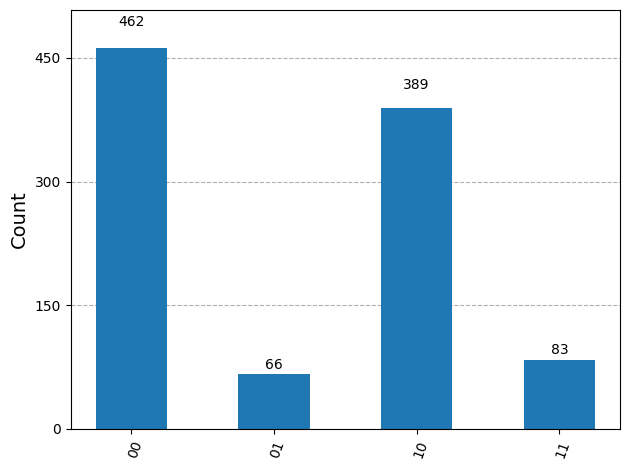

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# --------------------------
# Original Feature
# --------------------------

age = 0.8
income = 1.5

# --------------------------
# Quantum Circuit
# --------------------------

qc = QuantumCircuit(2,2)

# --------------------------
# Feature Encoding
# --------------------------

qc.ry(age,0)
qc.ry(income,1)

# --------------------------
# Feature Interaction
# --------------------------

qc.cx(0,1)

# --------------------------
# Feature Transformation
# --------------------------

qc.rz(age*income,1)

# --------------------------
# Measurement
# --------------------------

qc.barrier()

qc.measure([0,1],[0,1])

# --------------------------
# Circuit
# --------------------------

print(qc)

qc.draw("mpl")

# --------------------------
# Simulation
# --------------------------

sim = AerSimulator()

job = sim.run(qc,shots=1000)

result = job.result()

counts = result.get_counts()

fig_hist = plot_histogram(counts)
display(fig_hist)

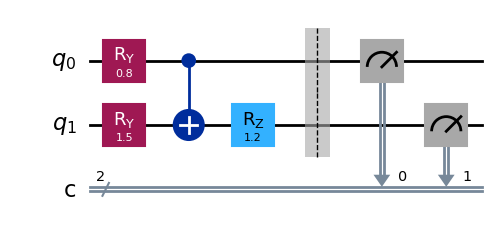

In [3]:
fig = qc.draw("mpl")
display(fig)